# DistilBERT test evaluation

Evaluate `best_model.safetensors` on all reviewed gold-standard test pairs in `data/5_golden_standard_pair/golden_standard_pair_complete/gs_pair_test.csv`. Compare `threshold=0.50` with the validation-selected cutoff in `tuned_threshold.json`.

Use the same `brandName`, `activeSubstances`, and `licenceHolder` serialization as training. Report macro F1, plot confusion matrices and macro F1 by `source_pair` and `hard`, and inspect errors at the tuned cutoff. Save predictions, metrics, and figures directly in this folder. Load the existing local files for this evaluation.

In [1]:
import os
import json
import time
from pathlib import Path

os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DistilBertConfig, DistilBertForSequenceClassification
from safetensors.torch import save_model, load_model
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.model_selection import train_test_split

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'data/5_golden_standard_pair').exists())
work_dir = project_root / 'notebooks/PLM_DistilBERT'
pretrained_dir = work_dir / 'pretrained'
data_dir = project_root / 'data/5_golden_standard_pair/golden_standard_pair_complete'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))
print(f'Device: {device}')

Device: cpu


## Tokenization

- `make_dataset`: serialize the selected attributes of both medicines and convert each labeled pair into token sequences.

In [2]:
def make_dataset(frame, tokenizer, attributes, max_length):
    """Serialize and tokenize medicine pairs with their binary labels.

    Parameters
    ----------
    frame : pandas.DataFrame
        Pair attributes with numeric suffixes and reviewed match labels.
    tokenizer : PreTrainedTokenizerBase
        Locally loaded tokenizer.
    attributes : list[str]
        Fields included in each record; excludes IDs and review metadata.
    max_length : int
        Maximum total tokens per pair, including special tokens.

    Returns
    -------
    TensorDataset
        Input IDs, attention masks, and labels in input row order.
    """
    texts = []
    for suffix in ['1', '2']:
        records = []
        for _, row in frame.iterrows():
            fields = []
            for attribute in attributes:
                value = row.get(attribute + suffix)
                value = '' if pd.isna(value) else ' '.join(str(value).split())
                fields.append(f'[COL] {attribute} [VAL] {value}')
            records.append(' '.join(fields))
        texts.append(records)
    encoded = tokenizer(texts[0], texts[1], padding='max_length',
                        truncation=True, max_length=max_length, return_tensors='pt')
    labels = torch.tensor(frame['match'].to_numpy(), dtype=torch.long)
    return TensorDataset(encoded['input_ids'], encoded['attention_mask'], labels)

## Model and threshold

Load `best_model.safetensors` with the existing configuration in `pretrained/`, and load the cutoff from `tuned_threshold.json`.

In [3]:
# Reuse the training input settings
batch_size = 16
max_length = 128
attributes = ['brandName', 'activeSubstances', 'licenceHolder']

checkpoint_path = work_dir / 'best_model.safetensors'
tokenizer = AutoTokenizer.from_pretrained(pretrained_dir, local_files_only=True)
model_config = DistilBertConfig.from_pretrained(pretrained_dir, local_files_only=True, num_labels=2)
model = DistilBertForSequenceClassification(model_config)
load_model(model, str(checkpoint_path))
model.to(device)
print('Loaded best model checkpoint.')
threshold_settings = json.loads((work_dir / 'tuned_threshold.json').read_text(encoding='utf-8'))
selected_threshold = threshold_settings['threshold']

Loaded best model checkpoint.


## Test probabilities

Evaluate all pairs in `gs_pair_test.csv`. Exclude `id1`, `id2`, `source_pair`, `hard`, and `match` from model inputs.

In [4]:
test_path = data_dir / 'gs_pair_test.csv'
test_pairs = pd.read_csv(test_path)
test_dataset = make_dataset(test_pairs, tokenizer, attributes, max_length)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
# Collect Test Loss and Match Probabilities
model.eval()
test_total_loss = 0.0
test_probabilities = []
with torch.inference_mode():
    for input_ids, attention_mask, labels in test_loader:
        output = model(input_ids=input_ids.to(device),
                       attention_mask=attention_mask.to(device), labels=labels.to(device))
        test_total_loss += output.loss.item() * len(labels)
        test_probabilities.extend(output.logits.softmax(dim=-1)[:, 1].cpu().tolist())
test_loss = test_total_loss / len(test_dataset)
test_probabilities = np.array(test_probabilities)
test_labels = test_pairs['match'].to_numpy()

test_predictions = test_pairs.copy()
test_predictions['match_probability'] = test_probabilities
test_predictions['pred_default'] = (test_probabilities >= 0.50).astype(int)
test_predictions['pred_tuned'] = (test_probabilities >= selected_threshold).astype(int)
test_predictions.to_csv(work_dir / 'test_predictions.csv', index=False)
print(f'Test pairs: {len(test_pairs)}; mean loss: {test_loss:.4f}')

Test pairs: 525; mean loss: 0.6160


## Metrics

Both cutoffs use the same test probabilities. Macro F1 averages the two classes equally.

In [5]:
metric_rows = []
for name, threshold in [('Default', 0.50), ('Validation-tuned', selected_threshold)]:
    macro_f1 = f1_score(test_labels, test_probabilities >= threshold,
                        labels=[0, 1], average='macro', zero_division=0)
    metric_rows.append({'configuration': name, 'threshold': threshold, 'macro_f1': macro_f1})
test_metrics = pd.DataFrame(metric_rows)
test_metrics.to_csv(work_dir / 'test_metrics.csv', index=False)
display(test_metrics.round(4))
evaluation_settings = {
    'test_file': test_path.name,
    'threshold': selected_threshold, 'test_pairs': len(test_pairs), 'test_loss': test_loss,
}
(work_dir / 'evaluation_config.json').write_text(json.dumps(evaluation_settings, indent=2), encoding='utf-8')

,configuration,threshold,macro_f1
0,Default,0.50,0.9193
1,Validation-tuned,0.17,0.9215


114

## Confusion matrices

Rows show actual labels; columns show predicted labels. Both matrices share the same count scale.

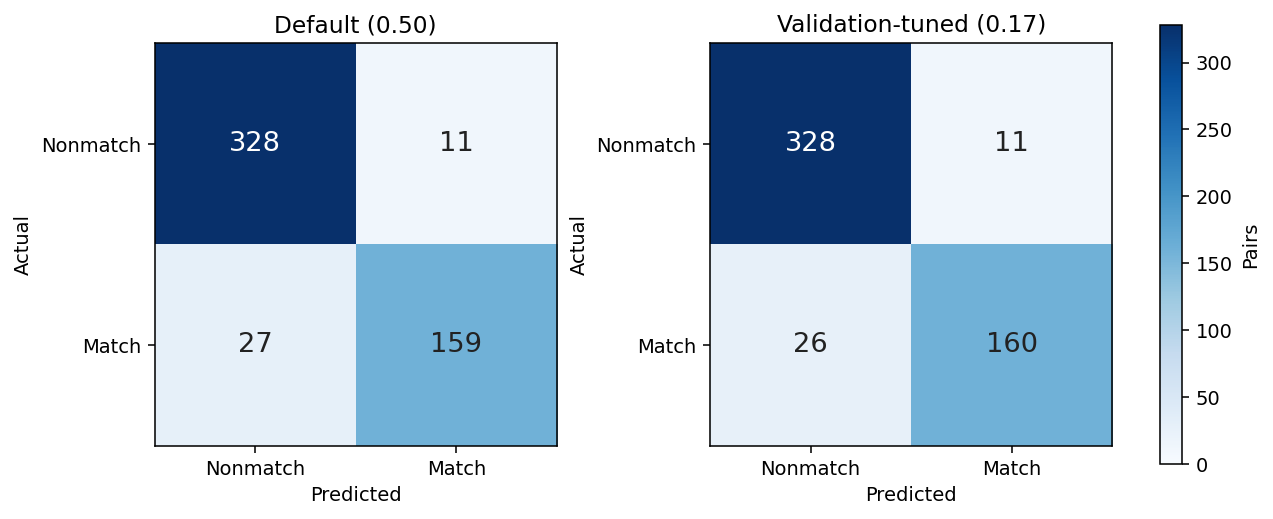

In [6]:
matrices = {
    'Default (0.50)': confusion_matrix(test_labels, test_predictions['pred_default'], labels=[0, 1]),
    f'Validation-tuned ({selected_threshold:.2f})': confusion_matrix(test_labels, test_predictions['pred_tuned'], labels=[0, 1]),
}
max_count = max(matrix.max() for matrix in matrices.values())
fig, axes = plt.subplots(1, 2, figsize=(9, 4), dpi=140, layout='constrained')
for ax, (label, matrix) in zip(axes, matrices.items()):
    image = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=max_count)
    ax.set_xticks([0, 1], ['Nonmatch', 'Match'])
    ax.set_yticks([0, 1], ['Nonmatch', 'Match'])
    ax.set(xlabel='Predicted', ylabel='Actual', title=label)
    for row in range(2):
        for col in range(2):
            ax.text(col, row, str(matrix[row, col]), ha='center', va='center', fontsize=14,
                    color='white' if matrix[row, col] > max_count / 2 else '#222222')
fig.colorbar(image, ax=axes, label='Pairs', shrink=0.8)
fig.savefig(work_dir / 'test_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

## Source pairs and difficulty

Compare macro F1 at both cutoffs within each `source_pair` and `hard` group. The saved `hard` label identifies ordinary (`0`) and difficult (`1`) pairs.

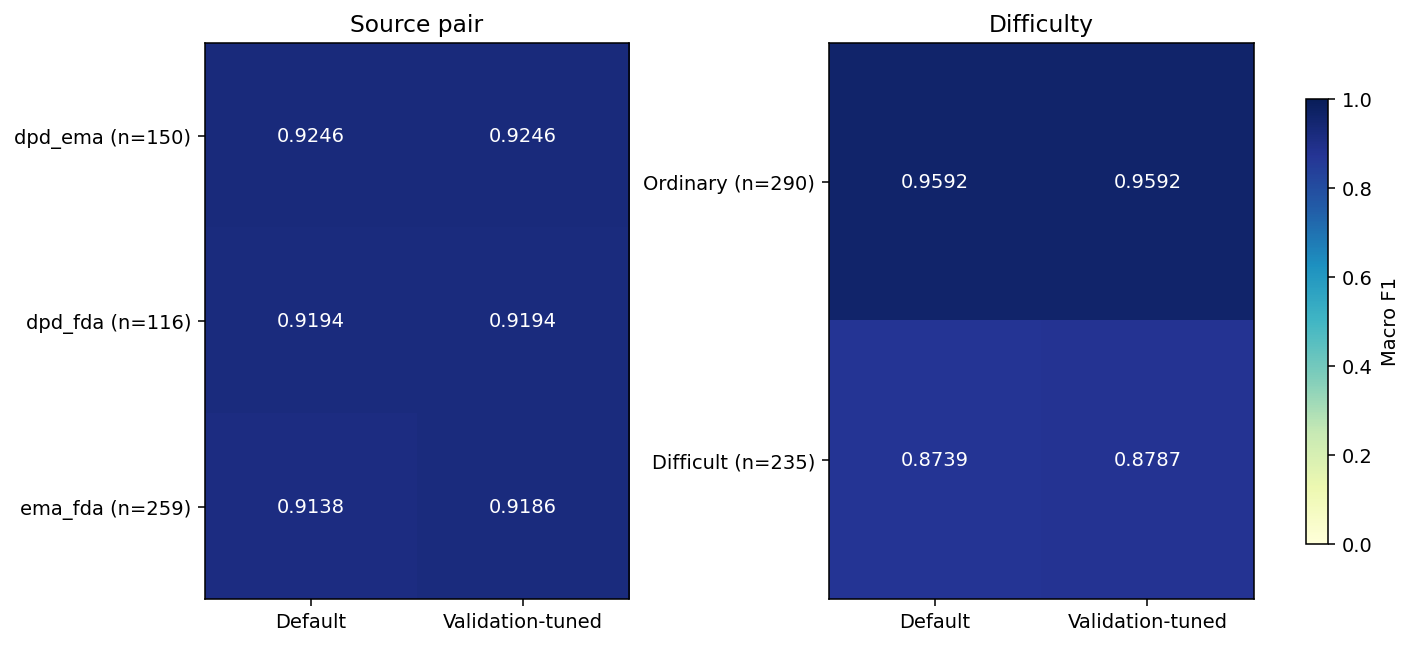

In [7]:
group_rows = []
for column in ['source_pair', 'hard']:
    for value, group in test_predictions.groupby(column):
        for name, threshold in [('Default', 0.50), ('Validation-tuned', selected_threshold)]:
            group_rows.append({
                'group': column, 'value': str(value), 'configuration': name, 'pairs': len(group),
                'macro_f1': f1_score(group['match'], group['match_probability'] >= threshold,
                                     labels=[0, 1], average='macro', zero_division=0),
            })
group_metrics = pd.DataFrame(group_rows)
group_metrics.to_csv(work_dir / 'test_group_metrics.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), dpi=140, layout='constrained')
for ax, column in zip(axes, ['source_pair', 'hard']):
    rows = group_metrics[group_metrics['group'] == column]
    chart = rows.pivot(index='value', columns='configuration', values='macro_f1')
    chart = chart.reindex(columns=['Default', 'Validation-tuned'])
    image = ax.imshow(chart, cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
    counts = rows.groupby('value')['pairs'].first()
    labels = [f'{value} (n={counts[value]})' for value in chart.index]
    if column == 'hard':
        labels = [f"{'Ordinary' if value == '0' else 'Difficult'} (n={counts[value]})" for value in chart.index]
    ax.set_yticks(range(len(chart)), labels)
    ax.set_xticks([0, 1], chart.columns)
    ax.set_title('Source pair' if column == 'source_pair' else 'Difficulty')
    for row in range(len(chart)):
        for col in range(2):
            value = chart.iloc[row, col]
            ax.text(col, row, f'{value:.4f}', ha='center', va='center',
                    color='white' if value > 0.6 else '#222222')
fig.colorbar(image, ax=axes, label='Macro F1', shrink=0.8)
fig.savefig(work_dir / 'test_group_macro_f1.png', dpi=300, bbox_inches='tight')
plt.show()

## False positives

Examples accepted at the validation-selected cutoff with a reviewed `match=0` label.

In [8]:
review_columns = ['source_pair', 'brandName1', 'brandName2', 'activeSubstances1', 'activeSubstances2', 'licenceHolder1', 'licenceHolder2', 'match_probability', 'match']
false_positives = test_predictions[(test_predictions['match'] == 0) & (test_predictions['pred_tuned'] == 1)]
print(f'False positives: {len(false_positives)}')
display(false_positives[review_columns].head(6))

False positives: 11


,source_pair,brandName1,brandName2,activeSubstances1,activeSubstances2,licenceHolder1,licenceHolder2,match_probability,match
28,dpd_ema,TEVIMBRA,Tevimbra,TISLELIZUMAB,tislelizumab,BEONE MEDICINES I GMBH,Beone Medicines Ireland Limited,0.999845,0
95,ema_fda,Natpar,NATPARA,parathyroid hormone,PARATHYROID HORMONE,Takeda Pharmaceuticals International AG Irelan...,NPS PHARMS INC,0.993532,0
98,dpd_fda,ADVIL COLD AND SINUS NIGHTTIME,ADVIL COLD AND SINUS,CHLORPHENIRAMINE; IBUPROFEN; PSEUDOEPHEDRINE,IBUPROFEN; PSEUDOEPHEDRINE HYDROCHLORIDE,HALEON CANADA ULC,HALEON US HOLDINGS,0.999775,0
220,dpd_fda,ALPHAGAN,ALPHAGAN P,BRIMONIDINE,BRIMONIDINE TARTRATE,ABBVIE CORPORATION,ABBVIE,0.999503,0
224,ema_fda,Eurneffy,NEFFY,epinephrine,EPINEPHRINE,ALK-Abelló A/S,ARS PHARMS OPERATION,0.999633,0
235,dpd_ema,MINT-CAPECITABINE,Capecitabine SUN,CAPECITABINE,capecitabine,MINT PHARMACEUTICALS INC,Sun Pharmaceutical Industries Europe B.V.,0.998727,0


## False negatives

Examples rejected at the validation-selected cutoff with a reviewed `match=1` label.

In [9]:
false_negatives = test_predictions[(test_predictions['match'] == 1) & (test_predictions['pred_tuned'] == 0)]
print(f'False negatives: {len(false_negatives)}')
display(false_negatives[review_columns].head(6))

False negatives: 26


,source_pair,brandName1,brandName2,activeSubstances1,activeSubstances2,licenceHolder1,licenceHolder2,match_probability,match
16,dpd_fda,MYFEMBREE,MYFEMBREE,ESTRADIOL; NORETHINDRONE; RELUGOLIX,ESTRADIOL; NORETHINDRONE ACETATE; RELUGOLIX,KNIGHT THERAPEUTICS INC.,SUMITOMO PHARMA AM,0.000752,1
32,ema_fda,Noxafil,NOXAFIL,posaconazole,POSACONAZOLE,Merck Sharp and Dohme B.V,SCHERING,0.000084,1
81,ema_fda,Alkindi,ALKINDI SPRINKLE,hydrocortisone,HYDROCORTISONE,Immedica Pharma AB,ETON,0.000035,1
107,dpd_ema,RHEUMOCAM INJECTION,Rheumocam,MELOXICAM,meloxicam,CHANELLE PHARMACEUTICALS MANUFACTURING LIMITED,NaN,0.000099,1
141,dpd_ema,ZONTIVITY,Zontivity,VORAPAXAR,vorapaxar sulfate,"XSPIRE PHARMA, LLC",Merck Sharp Dohme Limited,0.000029,1
158,dpd_fda,TRAVATAN Z,TRAVATAN Z,TRAVOPROST,TRAVOPROST,NOVARTIS PHARMACEUTICALS CANADA INC,SANDOZ,0.000038,1


## Macro F1 comparison

Compare the default cutoff of `0.50` and the cutoff from `tuned_threshold.json` on the same test pairs.

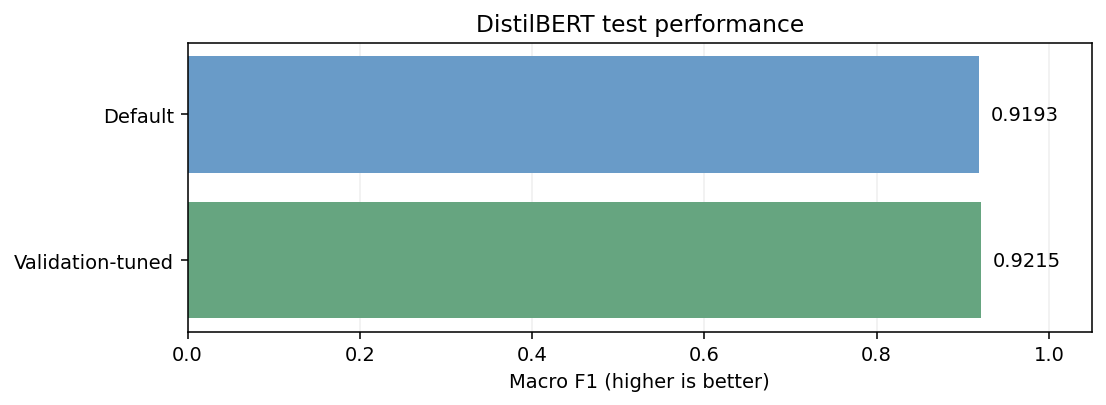

In [10]:
fig, ax = plt.subplots(figsize=(8, 3), dpi=140)
bars = ax.barh(test_metrics['configuration'], test_metrics['macro_f1'], color=['#699bc8', '#66a580'])
ax.bar_label(bars, labels=[f'{value:.4f}' for value in test_metrics['macro_f1']], padding=6)
ax.set(xlabel='Macro F1 (higher is better)', xlim=(0, 1.05), title='DistilBERT test performance')
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(work_dir / 'test_macro_f1.png', dpi=300, bbox_inches='tight')
plt.show()